# 03 Quando os dados mudam, o modelo continua confiável?

Nos notebooks anteriores conhecemos os dados e registramos um modelo de referência.
Agora vamos mudar o perfil dos clientes, visualizar o drift e acompanhar os alertas.

**Execute depois do notebook 02**, de cima para baixo. O modelo permanece congelado.
Este notebook reúne a simulação, os histogramas e o monitoramento dos antigos 03 e 04.


## 1. Qual é o ponto de partida?

Recuperamos o modelo pelo MLflow e as mesmas partições do treino. Os 4.000 registros
de produção estão separados dos 12.000 usados para treinar. Os conjuntos representam
uma simulação, pois a base não oferece datas de calendário para acompanhar meses reais.


In [1]:
import sys
from datetime import UTC, datetime
from pathlib import Path

from IPython.display import Markdown, display

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(project_root))

from ml_prep_kit import (
    CSVDataLoader,
    DataValidator,
    DriftMonitor,
    ExperimentTracker,
    HomeCreditData,
    ModelPredictor,
    VisualizationReporter,
)

/opt/venv/lib/python3.12/site-packages/evidently/descriptors/text_match.py:140: SyntaxWarning: invalid escape sequence '\d'
  TextMatch(text_column="description", match_items=r"\b\d{3}-\d{3}-\d{4}\b", match_type="regex")


/opt/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
processed_path = project_root / "data/processed"
preparation = HomeCreditData()
validator = DataValidator()
reporter = VisualizationReporter()
experiment = preparation.load_experiment(processed_path)
preparation.random_state = experiment["random_state"]
partitions = experiment["partitions"]
reference, production = partitions["treino"], partitions["producao"]
predictor = ModelPredictor.from_mlflow(
    experiment["model_uri"], tracking_uri=experiment["tracking_uri"]
)
version_one = CSVDataLoader(processed_path).load({"v1": "credit_scoring.csv"})["v1"]
display(validator.summarize({"Referência (treino)": reference, "Produção": production}))

,dataset,rows,columns,memory_mb
0,Referência (treino),12000,12,3.202961
1,Produção,4000,12,1.067339


## 2. Onde aparece a mudança de perfil?

Criamos uma segunda versão da base: **renda 30% menor e crédito 40% maior**.
Os outros campos, inclusive idade, identificador e alvo, são preservados.
A geração parte sempre da v1, sem acumular alterações ao reexecutar.


In [3]:
income_factor, credit_factor = 0.70, 1.40
version_two_path = processed_path / "credit_scoring_v2.csv"
version_two = preparation.create_drift_version(
    version_one,
    income_factor=income_factor,
    credit_factor=credit_factor,
    output_path=version_two_path,
)
display(validator.summarize({"Base v1": version_one, "Base v2": version_two}))

,dataset,rows,columns,memory_mb
0,Base v1,20000,12,5.185859
1,Base v2,20000,12,5.185859


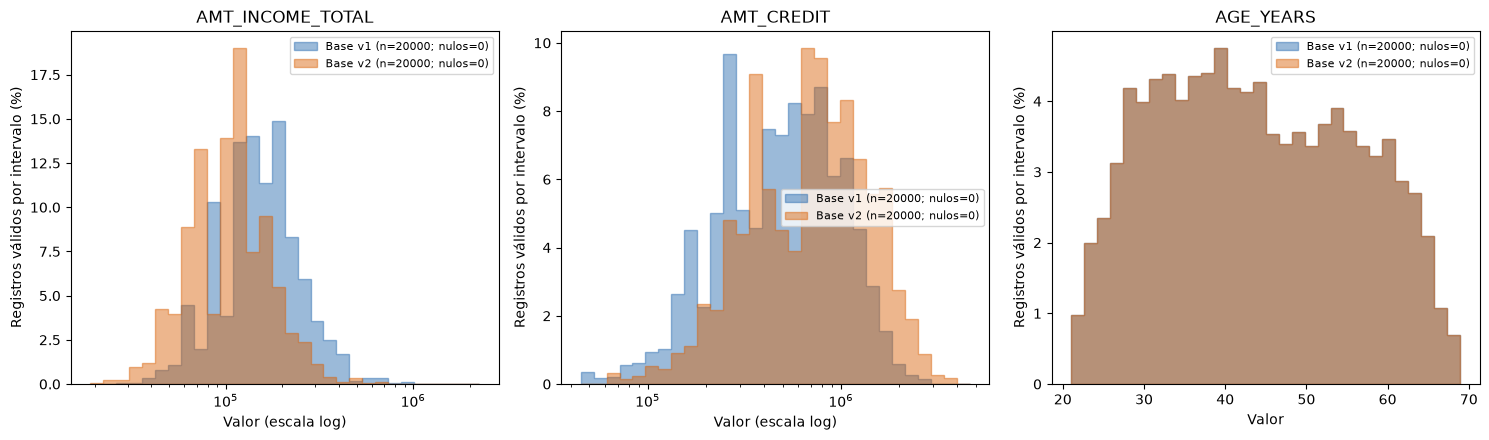

In [4]:
histograms = reporter.plot_overlaid_histograms(
    version_one,
    version_two,
    columns=["AMT_INCOME_TOTAL", "AMT_CREDIT", "AGE_YEARS"],
    log_columns=["AMT_INCOME_TOTAL", "AMT_CREDIT"],
    labels=("Base v1", "Base v2"),
)

**Como ler:** azul é a v1; laranja é a v2. Renda se desloca para valores menores,
crédito para maiores e idade permanece sobreposta. Os intervalos são comuns e cada
base soma 100% dos registros válidos. A escala logarítmica mostra os extremos sem
cortá-los; os dados usados no modelo continuam na escala original.

O CSV v2 tem 20.000 registros. **Somente seus IDs reservados para produção** entram
na comparação estatística com o treino; as versões completas servem à ilustração pareada.


## 3. Quais situações o monitor precisa reconhecer?

| Cenário | O que muda | O que investigar |
| --- | --- | --- |
| Controle | Nada | Variação natural frente ao treino |
| Dados inválidos | Renda nula, idade negativa e ID duplicado | Bloqueio antes da predição |
| Data drift | Renda e crédito da base v2 | Distribuições diferentes |
| Concept drift | Desfechos de parte dos clientes com renda alta | Desempenho com entradas iguais |

No concept drift, alteramos rótulos de parte dos casos negativos acima do terceiro
quartil de renda do treino, com seed fixa. É um choque **sintético**, não um evento
comprovado na população original. No data drift, os rótulos originais são mantidos
apenas para a comparação didática; não são novos desfechos observados.


In [5]:
scenarios, concept_metadata = preparation.scenarios(production, reference)
partitions_v2 = preparation.prepare_version(version_two, partitions)
scenarios["data_drift"] = partitions_v2["producao"]
print(f"Desfechos alterados no concept drift: {concept_metadata['changed_labels']}.")

Desfechos alterados no concept drift: 547.


## 4. O monitor detectou os problemas?

O mesmo contrato Pandera valida cada lote antes do modelo. O Evidently compara
as dez features com o treino: **KS < 0,01** nas numéricas e **PSI ≥ 0,20** nas
categóricas. O alerta de drift exige ao menos 20% das features alteradas; o de
desempenho, queda de AUC de pelo menos 0,05 frente ao controle.

São limiares demonstrativos. Valor-p não mede gravidade, e uma feature crítica
pode exigir uma regra própria. Sem rótulos, a avaliação de desempenho fica indisponível.

Os avisos técnicos da execução ficam na saída recolhida da célula; expanda-a para consultá-los.


In [6]:
execution_id = datetime.now(UTC).strftime("%Y%m%dT%H%M%S%fZ")
execution_path = processed_path / "monitoring" / execution_id
monitor = DriftMonitor(
    numeric_columns=preparation.numeric_features,
    categorical_columns=preparation.categorical_features + preparation.binary_features,
    output_dir=execution_path,
    ks_threshold=0.01,
    psi_threshold=0.20,
    drift_share=0.20,
    auc_drop_threshold=0.05,
)

In [7]:
tracker = ExperimentTracker(
    "tech-challenge-4-fintech",
    tracking_uri=experiment["tracking_uri"],
    artifact_location=(processed_path / "monitoring/mlartifacts").as_uri(),
)
parameters = {
    **concept_metadata,
    "seed": preparation.random_state,
    "income_factor": income_factor,
    "credit_factor": credit_factor,
    "concept_labels": "synthetic",
}
tags = {
    "training_run_id": experiment["training_run_id"],
    "model_uri": experiment["model_uri"],
    "v1_sha256": preparation.source_hash(processed_path / "credit_scoring.csv"),
    "v2_sha256": preparation.source_hash(version_two_path),
}

In [8]:
monitoring = monitor.evaluate_scenarios(
    scenarios=scenarios,
    reference=reference,
    predictor=predictor,
    contract=preparation.contract,
    target=preparation.target,
    tracker=tracker,
    threshold=experiment["threshold"],
    parameters=parameters,
    tags=tags,
    figures={"histogramas_v1_v2": histograms},
)
results, summary = monitoring["results"], monitoring["summary"]

2026/10/29 19:43:21 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet



2026/10/29 19:43:21 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git branch is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet



2026/10/29 19:43:21 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git repository URL is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet



In [9]:
labels = {
    "quality_passed": "Contrato válido",
    "predicted_rows": "Predições",
    "duration_seconds": "Duração (s)",
    "drifted_features": "Features em drift",
    "roc_auc": "ROC AUC",
    "drift_alert": "Alerta de drift",
    "performance_alert": "Alerta de desempenho",
}
display(summary[list(labels)].rename(columns=labels).round(3).fillna("—"))
display(results["dados_invalidos"]["quality_failures"])

,Contrato válido,Predições,Duração (s),Features em drift,ROC AUC,Alerta de drift,Alerta de desempenho
controle,1.0,4000.0,0.381,0.0,0.602,0.0,—
dados_invalidos,0.0,0.0,0.010,—,—,—,—
data_drift,1.0,4000.0,0.302,2.0,0.602,1.0,0.0
concept_drift,1.0,4000.0,0.420,0.0,0.456,0.0,1.0


,column,check,violations
0,AGE_YEARS,"in_range(18, 100)",1
1,AMT_INCOME_TOTAL,not_nullable,1
2,SK_ID_CURR,field_uniqueness,2


**Leia os alertas como 1 = sim, 0 = não e — = não avaliado.** O lote inválido
deve ter zero predições. A tabela de violações explica quais regras o bloquearam.
Uma renda menor, porém válida, passa no contrato e pode ser sinalizada pelo teste de drift.


,feature,method,score,threshold
1,AMT_INCOME_TOTAL,ks,0.000000e+00,0.01
2,AMT_CREDIT,ks,6.947000e-102,0.01


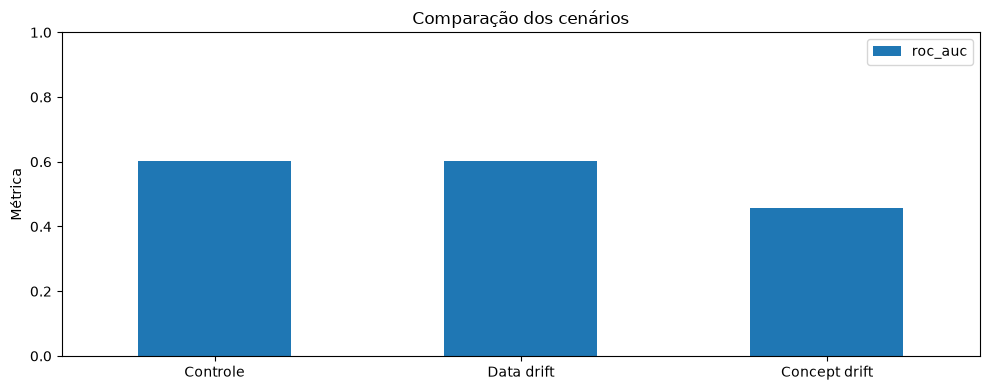

In [10]:
drift = results["data_drift"]["drift_table"]
display(drift.loc[drift["drift"], ["feature", "method", "score", "threshold"]])
_ = reporter.plot_metrics(
    summary.loc[["controle", "data_drift", "concept_drift"]].rename(
        index={
            "controle": "Controle",
            "data_drift": "Data drift",
            "concept_drift": "Concept drift",
        }
    ),
    ["roc_auc"],
)

## 5. O que concluímos e qual seria a resposta?

Leia em conjunto os histogramas, as features sinalizadas e a AUC acima.
**Data drift pode existir sem queda de desempenho.** No concept drift, as entradas
e os scores permanecem iguais ao controle; são os novos rótulos que permitem revelar
a mudança. A prevalência também muda, por isso aumentos de F1 ou Average Precision
isoladamente não demonstram recuperação.

| Sinal | Resposta proposta |
| --- | --- |
| Contrato violado | Bloquear o lote e corrigir a origem |
| Distribuição alterada | Investigar coleta e perfil dos clientes |
| Desempenho degradado | Obter rótulos recentes e comparar um candidato em dados independentes |

Este notebook valida, detecta e registra mantendo o modelo congelado. O comando
`python -m src.credit_monitoring` reutiliza o `ml_prep_kit` para retreinar quando há
alerta e rótulos suficientes. Compara o candidato no mesmo teste reservado e promove
somente se os critérios forem atendidos; a API permite retornar à versão anterior.
Prometheus e Grafana exibem as métricas. Airflow e AWS permanecem evoluções.
Veja os comandos e resultados no [README](../README.md).


In [11]:
for name in ["controle", "data_drift", "concept_drift"]:
    relative_path = (execution_path / f"{name}.html").relative_to(project_root)
    display(Markdown(f"[Relatório Evidently: {name}](../{relative_path})"))
print(f"Execução MLflow: {monitoring['run_id']}")
print(f"Artefatos locais: {execution_path.relative_to(project_root)}")

[Relatório Evidently: controle](../data/processed/monitoring/20261029T194321489892Z/controle.html)

[Relatório Evidently: data_drift](../data/processed/monitoring/20261029T194321489892Z/data_drift.html)

[Relatório Evidently: concept_drift](../data/processed/monitoring/20261029T194321489892Z/concept_drift.html)

Execução MLflow: ff1d41a3c951458daaef24aef5dc725a
Artefatos locais: data/processed/monitoring/20261029T194321489892Z


Os histogramas, relatórios completos, logs de volume/duração/status e métricas
estão vinculados ao treinamento no MLflow. A base v2 e os dados individuais ficam
fora do Git. O Grafana acompanha as etapas; CPU, memória e disco ficam disponíveis
com o perfil `infra` do Compose, conforme o [README](../README.md).

**Entrega da FIAP:** o README reúne governança, vieses e análise causal. A publicação
na `main` e o vídeo STAR de até cinco minutos permanecem pendentes. Idade e escolaridade
merecem atenção a vieses. Os cenários sintéticos não provam causas econômicas reais.

<details>
<summary>Abrir o MLflow pelo Docker</summary>

Na raiz do projeto, execute:

```bash
docker compose --file docker/docker-compose.yml run --rm -p 5000:5000 notebook \
  mlflow ui --host 0.0.0.0 --port 5000 \
  --backend-store-uri sqlite:////app/data/processed/monitoring/mlflow.db
```

Acesse http://localhost:5000. Use o mesmo ambiente e a montagem `/app` que geraram
os artefatos; execuções locais dependem de seus caminhos originais.

</details>
